# Lecture 9–13 综合复习 Notebook
## 知识点 · 代表题 · 参考代码 · 中文解释

依据你提供的 Lecture 9–13、Lecture 10 exercises、Lecture 13 solutions、practice quiz 3 和 Lab 5 with solutions 整理。中文解释为主，保留英文术语与题目常用表达。

**使用方法**：每节先看知识点，再自己尝试题目，最后运行参考代码。所有数据都内置，无需 features.csv；默认 Run All 不会停在 input()，也不会因为故意演示的错误而中断。交互题在最后把开关改成 True 后单独运行。

**范围说明**：极坐标与 keyword-only 的 `*` 来自 practice quiz F（Lab 5），与Lab 5专节一并收录；不把它误归为 Lecture 9–13 的主要内容。生日模型统一使用 Lecture 13 的 **360 天**，不是此前练习中使用的 365 天。

## 目录
1. Lecture 9：字典、嵌套字典、循环与 DataFrame
2. Lecture 10：函数、返回值、作用域与模拟
3. Lecture 11：lambda、apply、绘图与修改输入
4. Lecture 12：错误、异常与 input 验证
5. Lecture 13：silent errors、assert、debugging 与缺失数据
6. Practice quiz A–F 对照与 keyword-only 补充
7. 交互练习与考前速查
8. Lab 5：keyword-only、*args、**kwargs 与可选绘图设置

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 让此份复习结果可复现；不要在每次模拟函数内部重置 seed。
random.seed(2026)
np.random.seed(2026)
print("Setup ready")

Setup ready


In [2]:
lab_partners = {
    "Abed":      {"month": "March",     "day": 23, "year": 2007, "lab_skills": 3.24},
    "Britta":    {"month": "July",      "day": 14, "year": 1998, "lab_skills": 1.51},
    "Jeff":      {"month": "December",  "day": 8,  "year": 1990, "lab_skills": 0.51},
    "Shirley":   {"month": "January",   "day": 19, "year": 1990, "lab_skills": 6.72},
    "Annie":     {"month": "September", "day": 27, "year": 2007, "lab_skills": 6.72},
    "Troy":      {"month": "June",      "day": 5,  "year": 2007, "lab_skills": 3.66},
    "Pierce":    {"month": "December",  "day": 30, "year": 1962, "lab_skills": 0.58},
    "Chang":     {"month": "April",     "day": 17, "year": 1987, "lab_skills": 5.07},
    "Craig":     {"month": "August",    "day": 11, "year": 1985, "lab_skills": 0.37},
    "Magnitude": {"month": "February",  "day": 22, "year": 1983, "lab_skills": 4.34},
    "Garrett":   {"month": "October",   "day": 3,  "year": 2001, "lab_skills": 0.70},
    "Vicki":     {"month": "May",       "day": 29, "year": 2003, "lab_skills": 0.91},
    "Todd":      {"month": "March",     "day": 16, "year": 1997, "lab_skills": 9.99},
    "Starburns": {"month": "July",      "day": 7,  "year": 1982, "lab_skills": 8.27},
    "Neil":      {"month": "January",   "day": 25, "year": 1998, "lab_skills": 1.24},
    "Leonard":   {"month": "November",  "day": 13, "year": 1993, "lab_skills": 2.23},
    "Willy":     {"month": "September", "day": 4,  "year": 1981, "lab_skills": 6.27},
    "Pavel":     {"month": "June",      "day": 21, "year": 1980, "lab_skills": 9.48},
    "Quendra":   {"month": "December",  "day": 9,  "year": 1982, "lab_skills": 5.77},
    "Rich":      {"month": "April",     "day": 28, "year": 1986, "lab_skills": 3.97},
    "Duncan":    {"month": "August",    "day": 15, "year": 1987, "lab_skills": 9.76},
    "Hickey":    {"month": "February",  "day": 6,  "year": 1996, "lab_skills": 0.47},
    "Buzz":      {"month": "October",   "day": 24, "year": 1999, "lab_skills": 8.58},
    "Rachel":    {"month": "May",       "day": 18, "year": 1980, "lab_skills": 2.90},
    "Ian":       {"month": "March",     "day": 12, "year": 1997, "lab_skills": 1.44},
    "Elroy":     {"month": "July",      "day": 30, "year": 1986, "lab_skills": 1.18},
    "Frankie":   {"month": "November",  "day": 2,  "year": 2002, "lab_skills": 3.08},
    "Natalie":   {"month": "September", "day": 20, "year": 2000, "lab_skills": 8.16},
    "Owen":      {"month": "June",      "day": 11, "year": 2002, "lab_skills": 1.81},
    "Paula":     {"month": "December",  "day": 26, "year": 1997, "lab_skills": 5.82},
    "Quinn":     {"month": "April",     "day": 1,  "year": 1993, "lab_skills": 6.39},
    "Roger":     {"month": "August",    "day": 17, "year": 1987, "lab_skills": 3.72},
    "Sara":      {"month": "February",  "day": 8,  "year": 1994, "lab_skills": 5.48},
    "Tim":       {"month": "October",   "day": 22, "year": 1998, "lab_skills": 0.63},
    "Uma":       {"month": "May",       "day": 14, "year": 1988, "lab_skills": 0.60},
    "Victor":    {"month": "January",   "day": 29, "year": 2005, "lab_skills": 2.06},
    "Wendy":     {"month": "July",      "day": 5,  "year": 2007, "lab_skills": 6.80},
    "Xavier":    {"month": "March",     "day": 19, "year": 1980, "lab_skills": 4.28},
    "Yolanda":   {"month": "November",  "day": 10, "year": 2004, "lab_skills": 3.14},
    "Zara":      {"month": "September", "day": 3,  "year": 2005, "lab_skills": 5.86},
    "Alex":      {"month": "June",      "day": 27, "year": 1985, "lab_skills": 4.53},
    "Blake":     {"month": "December",  "day": 16, "year": 2002, "lab_skills": 3.00},
    "Casey":     {"month": "April",     "day": 7,  "year": 1993, "lab_skills": 7.94},
    "Dana":      {"month": "August",    "day": 23, "year": 1990, "lab_skills": 6.99},
    "Eli":       {"month": "February",  "day": 18, "year": 1988, "lab_skills": 2.44},
    "Fiona":     {"month": "October",   "day": 12, "year": 1984, "lab_skills": 5.74},
    "George":    {"month": "May",       "day": 25, "year": 1986, "lab_skills": 5.25},
    "Hana":      {"month": "January",   "day": 6,  "year": 2004, "lab_skills": 8.75},
    "Ivan":      {"month": "July",      "day": 21, "year": 1990, "lab_skills": 7.29},
    "Julia":     {"month": "March",     "day": 15, "year": 1983, "lab_skills": 2.88},
}

months = ["January", "February", "March", "April",
          "May", "June", "July", "August",
          "September", "October", "November", "December"]

print(len(lab_partners), "potential lab partners")

50 potential lab partners


## 1. Lecture 9 — Dictionaries

| 方法 | 含义 | 示例 |
|---|---|---|
| `{key: value}` | 建立字典；key 唯一 | `{"Todd": 9.99}` |
| `d[key]` | 按 key 查值，不按位置 | `scores["Todd"]` |
| `d[key] = value` | 已有 key 则更新，否则新增 | `scores["Jeff"] = 2.51` |
| `d.keys()` / `d.values()` | keys / values 的 view | `list(d.values())` 转成 list |
| `for name in d` | 默认遍历 keys | value 用 `d[name]` 取出 |
| `d[name]["year"]` | 从左到右，两次查找 | 外层名字、内层属性 |
| `pd.DataFrame(d)` | 字典 key 成为列名 | 每列 list 长度必须相同 |

字符串 key 区分大小写，需要引号。`d["Todd"]` 与 `d[Todd]` 不同：后者把 Todd 当变量。字典没有的 key 会触发 KeyError。值可以是数字、字符串、list 或另一个字典。空字典为 `{}`。

`random.shuffle(names)` 原地打乱 list，返回 None。应先 `names = list(d.keys())`，再 shuffle；不要写 `names = random.shuffle(names)`。

### 题 1｜读取、更新、遍历（L9 Ex1）

**题目 / Try first**

打印 Duncan 的成绩，给 Chang 加 2 分，逐人打印成绩。

先自己尝试，再查看下面的参考代码。

In [3]:
quiz_scores = {"Chang": 6.5, "Duncan": 9.0, "Craig": 4.5, "Vicki": 7.5, "Garrett": 5.0}
print("Duncan:", quiz_scores["Duncan"])
quiz_scores["Chang"] = quiz_scores["Chang"] + 2
for name in quiz_scores:
    print(f"Quiz score for {name} : {quiz_scores[name]}")

Duncan: 9.0
Quiz score for Chang : 8.5
Quiz score for Duncan : 9.0
Quiz score for Craig : 4.5
Quiz score for Vicki : 7.5
Quiz score for Garrett : 5.0


**解释 / Why it works**

更新时使用原值，而非直接写 8.5。循环变量 name 是 key；`quiz_scores[name]` 才是成绩。若只重复运行加分一行会反复加分，完整 cell 会先重新初始化。

### 题 2｜Running maximum / minimum（L9、L13）

**题目 / Try first**

找到最高分和最低分的人；初始化不要依赖全部分数大于 0。

先自己尝试，再查看下面的参考代码。

In [4]:
names = list(quiz_scores.keys())
best_name = names[0]
best_score = quiz_scores[best_name]
worst_name = names[0]
worst_score = quiz_scores[worst_name]
for name in names:
    score = quiz_scores[name]
    if score > best_score:
        best_score = score
        best_name = name
    if score < worst_score:
        worst_score = score
        worst_name = name
print("Best:", best_name, best_score)
print("Worst:", worst_name, worst_score)
assert best_score == np.max(list(quiz_scores.values()))
assert worst_score == np.min(list(quiz_scores.values()))

Best: Duncan 9.0
Worst: Craig 4.5


**解释 / Why it works**

从真实的第一个观测值开始，前提是字典非空。每次更新数值时同时更新名字。最小值也可从 `float("inf")` 开始，最大值可从 `float("-inf")` 开始。固定从 0 开始需要额外的数据范围假设。

### 题 3｜最年长的人（Quiz A）

**题目 / Try first**

使用 oldest_year=3000 和 oldest_name="nobody"，只根据出生年份找最年长者。

先自己尝试，再查看下面的参考代码。

In [5]:
oldest_year = 3000
oldest_name = "nobody"
for name in lab_partners:
    year = lab_partners[name]["year"]
    if year < oldest_year:
        oldest_year = year
        oldest_name = name
print(f"The oldest member is {oldest_name}, born in {oldest_year}")

The oldest member is Pierce, born in 1962


**解释 / Why it works**

`lab_partners[name]` 是内部字典，第二个 ["year"] 取年份。年份越小年龄越大。答案 Pierce，1962；题目保证最年长者出生年份唯一，不需要比较月日。

### 题 4｜嵌套循环求每天平均值（Quiz B）

**题目 / Try first**

对任意选中城市，求每天的平均温度；不要固定城市数量。

先自己尝试，再查看下面的参考代码。

In [6]:
ga_temps = {
    "Atlanta": {"Monday": 78, "Tuesday": 81},
    "Savannah": {"Monday": 84, "Tuesday": 86},
    "Athens": {"Monday": 76, "Tuesday": 79}
}
days_of_week = ["Monday", "Tuesday"]
selected = random.sample(list(ga_temps.keys()), k=random.randint(2, 3))
cities_to_be_averaged = {}
for city in selected:
    cities_to_be_averaged[city] = ga_temps[city]
print("Selected:", selected)
for day in days_of_week:
    total_temp = 0
    for city in cities_to_be_averaged:
        total_temp += cities_to_be_averaged[city][day]
    average_temp = total_temp / len(cities_to_be_averaged)
    print(f"Average high on {day}: {average_temp:.2f} °F")

Selected: ['Savannah', 'Atlanta']
Average high on Monday: 81.00 °F
Average high on Tuesday: 83.50 °F


**解释 / Why it works**

练习简化为两天，七天完全相同。外层每换一天就把 total_temp 归零；内层累加城市温度。len 是实际选中城市数。random.sample 不重复抽取 k 个；randint 包含两端；:.2f 固定显示两位小数。

### 题 5｜字典转 DataFrame（L9 Ex3）

**题目 / Try first**

用四部电影的 title、year、rating 创建表格。

先自己尝试，再查看下面的参考代码。

In [7]:
movie_data = {
    "title": ["Movie A", "Movie B", "Movie C", "Movie D"],
    "year": [2005, 2012, 2019, 2024],
    "rating": [8.0, 9.0, 7.5, 8.5]
}
df_movies = pd.DataFrame(movie_data)
display(df_movies)

,title,year,rating
0,Movie A,2005,8.0
1,Movie B,2012,9.0
2,Movie C,2019,7.5
3,Movie D,2024,8.5


**解释 / Why it works**

各 list 必须等长；同一位置组成同一行。这里是虚构电影数据。

## 2. Lecture 10 — User-defined functions

```python
def function_name(parameter1, parameter2):
    result = ...
    return result
```

- **定义**：运行 def 建立函数；**调用**：`function_name(...)` 才执行内部代码。
- parameter 是定义时的名字；argument 是调用时提供的值。外面变量名不必与形参相同。
- 按位置调用看顺序；关键词调用看参数名。`f(2, 3)` 或 `f(x=2, y=3)`。
- `return` 返回值并立刻结束函数；`print` 只显示。没有 return 默认返回 None。
- `return a, b` 返回 tuple；`u, v = f(...)` 解包；一个变量接收则保存整个 tuple。
- 参数与函数内赋值的变量通常是 local。返回的是值，并不会把内部变量名变成 global。
- 函数可以读取 global，但把数据作为参数传入通常更易复用、测试。
- 括号很重要：`a / (2*b)` 不等于 `a / 2*b`。乘方用 `**`。

### 题 6｜复利函数 + lambda 对照（L10/11）

**题目 / Try first**

实现复利公式，计算两组 lecture 数据。

先自己尝试，再查看下面的参考代码。

In [8]:
def investment_value(P, r, n, t):
    return P * (1 + r / n) ** (n * t)

fn_investment = lambda P, r, n, t: P * (1 + r / n) ** (n * t)
for args in [(100, 0.01, 20, 10), (1000, 0.05, 35, 15)]:
    value = investment_value(*args)
    print(f"Final value: ${value:.2f}")
    assert np.isclose(value, fn_investment(*args))

Final value: $110.51
Final value: $2115.87


**解释 / Why it works**

年利率 1% 写为 0.01；r/n 是每期利率，n*t 是总期数。结果约 $110.51、$2115.87。此处 `*args` 是调用时把 tuple 解包为四个实参，与 Quiz F 定义中的单独 `*` 作用不同。也可直接写 investment_value(100, 0.01, 20, 10)。

### 题 7｜函数化 while：人口翻倍（Quiz C）

**题目 / Try first**

实现 years_to_double(growth_rate)，打印 1%、2%、5%、10% 的翻倍年数。

先自己尝试，再查看下面的参考代码。

In [9]:
def years_to_double(growth_rate):
    assert growth_rate > 0, "Growth rate must be positive"
    population = 1000
    years = 0
    while population < 2000:
        population = population * (1 + growth_rate)
        years += 1
    return years

for rate in [0.01, 0.02, 0.05, 0.10]:
    print(f"{rate:.0%}: {years_to_double(rate)} years")
assert [years_to_double(r) for r in [0.01, 0.02, 0.05, 0.10]] == [70, 36, 15, 8]

1%: 70 years
2%: 36 years
5%: 15 years
10%: 8 years


**解释 / Why it works**

每次调用重新初始化人口和年数。return 在 while 外；若在内部会只执行一年。正增长率检查防止 0 或负数导致无法达到翻倍目标。

### 题 8｜多返回值：二次公式（L10）

**题目 / Try first**

输入 a,b,c，返回两个实数根；观察单变量和两个变量接收的区别。

先自己尝试，再查看下面的参考代码。

In [10]:
def quadratic_formula(a, b, c):
    assert a != 0, "a must be nonzero"
    discriminant = b ** 2 - 4 * a * c
    assert discriminant >= 0, "This version handles real roots only"
    sqrt_d = np.sqrt(discriminant)
    return (-b + sqrt_d) / (2 * a), (-b - sqrt_d) / (2 * a)

roots = quadratic_formula(2, -4, -30)
root1, root2 = roots
print("Tuple:", roots)
print("Separate values:", root1, root2)

Tuple: (np.float64(5.0), np.float64(-3.0))
Separate values: 5.0 -3.0


**解释 / Why it works**

根为 5、−3。discriminant 是局部变量，外面直接访问这个名字不会获得函数内部值。输出变量可以取任何名字。assert 不处理复数根，限制了此版本的使用范围。

### 题 9｜向量与 divergence（L10 Ex4–6）

**题目 / Try first**

用三个子函数组合向量，再返回“向量 + 一个数”两个对象。

先自己尝试，再查看下面的参考代码。

In [11]:
def component1(x, y, z):
    return x * np.exp(y)
def component2(x, y, z):
    return np.exp(x * y)
def component3(x, y, z):
    return np.sin(y * z)
def vector_function(x, y, z):
    return np.array([component1(x,y,z), component2(x,y,z), component3(x,y,z)])
def F_and_divergence(x, y, z):
    vector = vector_function(x, y, z)
    divergence = np.exp(y) + x * np.exp(x*y) + y * np.cos(y*z)
    return vector, divergence

vector, divergence = F_and_divergence(1, 2, 3)
a, b, c = vector
print("Vector:", vector)
print("Divergence:", divergence)
(a, b, c), d = F_and_divergence(1, 2, 3)
print("Nested unpacking:", a, b, c, d)

Vector: [ 7.3890561  7.3890561 -0.2794155]
Divergence: 16.69845277116203
Nested unpacking: 7.38905609893065 7.38905609893065 -0.27941549819892586 16.69845277116203


**解释 / Why it works**

外层返回的是两个对象，所以直接 a,b,c,d = F_and_divergence(...) 会失败；可以使用嵌套解包。tuple、list、array 只要长度合适都能解包。讲义 divergence 推导第一行的第三项写成 ∂F3/∂x 是笔误，应为 ∂F3/∂z；给出的最终公式是正确的。

### 题 10｜累计成功 vs 连续成功（L10 Ex11–12）

**题目 / Try first**

编写函数，等待 k 次连续成功，单次成功概率 0.8。

先自己尝试，再查看下面的参考代码。

In [12]:
def trials_until_consecutive(k):
    assert type(k) == int and k >= 1
    streak = 0
    num_trials = 0
    while streak < k:
        outcome = np.random.choice(["Success", "Failure"], p=[0.8, 0.2])
        num_trials += 1
        if outcome == "Success":
            streak += 1
        else:
            streak = 0
    return num_trials

print("Trials until 3 consecutive successes:", trials_until_consecutive(3))

Trials until 3 consecutive successes: 11


**解释 / Why it works**

num_trials 每轮加 1；连续成功计数遇到失败必须归零。若只要求累计 k 次成功，失败时不要归零。返回值随机，不能要求每次相同。

## 3. Lecture 11 — Lambda, apply, no output, mutation

```python
fn = lambda x, y: expression
fn_pair = lambda x, y: (expression1, expression2)
result = df["column"].apply(fn)
```

lambda 自动返回表达式，不写 return。多输出用 tuple 括号。apply 对 Series 的每个元素调用函数，得到新 Series；传函数名，不写 `fn()`。需要保存到原表时显式赋值 `df["new"] = ...`。

`series.name = "New name"` 修改 Series 名称；`round(value, 2)` 四舍五入数值；`f"{value:.2f}"` 格式化为两位小数的字符串。

绘图函数可以没有显式 return，其效果是显示图；函数仍隐式返回 None。bar 用于类别比较，hist 用于数值分布。

### 题 11｜lambda 返回值与 gradient（L11 Ex2–3）

**题目 / Try first**

返回 f(x,y)=y+x²+2x+1 以及 gradient=(2x+2,1)。

先自己尝试，再查看下面的参考代码。

In [13]:
fn_value_gradient = lambda x, y: (y + x**2 + 2*x + 1, (2*x + 2, 1))
value, gradient = fn_value_gradient(2, 1)
print("Value:", value)
print("Gradient:", gradient)
assert value == 10 and gradient == (6, 1)

Value: 10
Gradient: (6, 1)


**解释 / Why it works**

外层 tuple 有两个元素：数值 10、gradient tuple (6,1)。不要把整个输出误认为三个平行的返回值。

### 题 12｜apply 判断成绩（Quiz D / L11 Ex4）

**题目 / Try first**

使用 if/else 函数，把成绩转换成 status 字符串并 display。

先自己尝试，再查看下面的参考代码。

In [14]:
df_grades = pd.DataFrame({"name": ["Chang", "Duncan", "Craig", "Vicki", "Garrett"],
                          "numeric_grade": [85, 90, 45, 75, 50]})
def grade_status(numeric_grade):
    if numeric_grade >= 55:
        return "status = pass"
    else:
        return "status = fail"
result = df_grades["numeric_grade"].apply(grade_status)
display(result)
# 另一个 lambda 示例：返回 Boolean
eligible = pd.Series([18, 29, 15, 32, 6]).apply(lambda age: age >= 18)
print("Voter eligibility:", eligible.tolist())

0    status = pass
1    status = pass
2    status = fail
3    status = pass
4    status = fail
Name: numeric_grade, dtype: str

Voter eligibility: [True, True, False, True, False]


**解释 / Why it works**

apply 分别传入 85、90、45、75、50，返回 pass、pass、fail、pass、fail。55 也及格。题目要求 if/else 时保留普通 def。

### 题 13｜单位转换与列名（L11）

**题目 / Try first**

把 mpg 转换成 km/L，保留两位小数。

先自己尝试，再查看下面的参考代码。

In [15]:
car_mpg = pd.Series([18.0, 25.0, 30.0], name="mpg")
convert = lambda mpg: round(mpg * 1.609344 / 3.785411784, 2)
car_kmL = car_mpg.apply(convert)
car_kmL.name = "km per liter"
display(car_kmL)

0     7.65
1    10.63
2    12.75
Name: km per liter, dtype: float64

**解释 / Why it works**

参数名可以自定，不必和列名相同。每一项都执行相同换算；使用自带小数据，避免依赖未上传 CSV。

### 题 14｜没有返回值的绘图函数（L10/11）

**题目 / Try first**

创建带标签的 histogram 与 bar plot。

先自己尝试，再查看下面的参考代码。

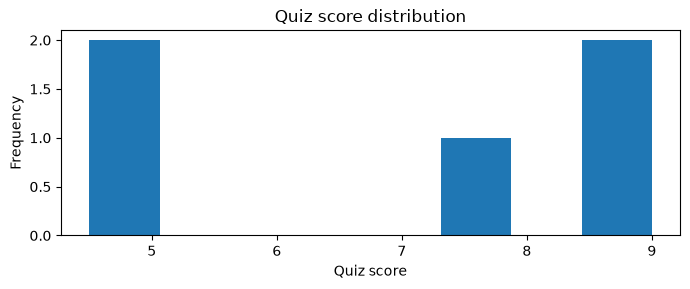

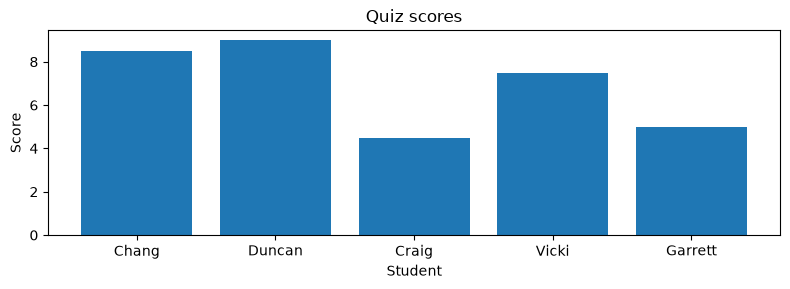

In [16]:
def create_histogram(vec_x, xlabel, title):
    plt.figure(figsize=(7, 3))
    plt.hist(vec_x, bins=8)
    plt.xlabel(xlabel)
    plt.ylabel("Frequency")
    plt.title(title)
    plt.tight_layout()
    plt.show()

def labeled_bar_plot(x_vals, heights, xlabel, ylabel, title):
    plt.figure(figsize=(8, 3))
    plt.bar(x=x_vals, height=heights)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.tight_layout()
    plt.show()

create_histogram(list(quiz_scores.values()), "Quiz score", "Quiz score distribution")
labeled_bar_plot(list(quiz_scores.keys()), list(quiz_scores.values()),
                 "Student", "Score", "Quiz scores")

**解释 / Why it works**

plt.figure 新建图；xlabel/ylabel/title 添加信息；show 显示。无需 answer = create_histogram(...)，因为返回值为 None。

### 题 15｜为什么 append 改了原 list，+ 却没有？（L11）

**题目 / Try first**

比较原地修改和局部变量重新绑定。

先自己尝试，再查看下面的参考代码。

In [17]:
def add_element(lst):
    lst.append("New!")
def add_element2(lst):
    lst = lst + ["New!"]
def add_element_return(lst):
    return lst + ["New!"]

x = [1, 2, 3]
y = [1, 2, 3]
add_element(x)
add_element2(y)
print("append:", x)
print("local rebinding:", y)
y = add_element_return(y)
print("return and assign:", y)

integer_array = np.array([1, 2, 3])
float_array = np.array([1, 2, 3], dtype=np.float64)
integer_array[-1] = 0.1
float_array[-1] = 0.1
print("Integer dtype:", integer_array)
print("Float dtype:", float_array)

append: [1, 2, 3, 'New!']
local rebinding: [1, 2, 3]
return and assign: [1, 2, 3, 'New!']
Integer dtype: [1 2 0]
Float dtype: [1.  2.  0.1]


**解释 / Why it works**

append、lst[-1]=... 修改同一个对象；lst = lst + [...] 创建新 list，只让局部名字指向新对象。若想使用新对象，需要 return 并在外面接收。整数 array 保存 0.1 时转成 0；float array 可以保留 0.1。

## 4. Lecture 12 — Errors, exceptions, input

| 错误 | 典型原因 |
|---|---|
| SyntaxError / IndentationError | 缺冒号、括号未配对、缩进不正确 |
| NameError | 变量未定义，或错误访问函数局部名字 |
| KeyError | 字典没有这个 key |
| IndexError | list 索引超出范围 |
| TypeError | 类型不支持操作，如字符串加数字 |
| ValueError | 转换值无效，如 int("lots") |
| ZeroDivisionError | 普通 Python 数值除以零 |

Traceback 从底部看错误类型与消息，再看出错行和调用链。Warning 通常不会停止运行；NumPy 无效除法可能给出 warning 和 nan，并不触发普通 ZeroDivisionError。

```python
try:
    risky_operation()
except ValueError:
    handle_expected_problem()
```

出错后跳过 try 剩余部分，转到匹配的 except。尽量写具体错误类型，避免 `except: pass` 隐藏问题。循环中打印或统计跳过的数据。

`input()` 总是返回字符串。`int()` 用于整数，`float()` 用于小数。数值转换成功不等于范围有效：`int("-3")` 成功，但可能不符合题意。

### 题 16｜跳过无效名字并记录（L12 Ex3）

**题目 / Try first**

打印生日；拼错名字不停止，统计找到和跳过的人数。

先自己尝试，再查看下面的参考代码。

In [18]:
guest_list = ["Shirley", "Shirlee", "Pavel", "Abed", "Abbed", "Zara"]
num_found = 0
num_skipped = 0
for name in guest_list:
    try:
        month = lab_partners[name]["month"]
        day = lab_partners[name]["day"]
        print(f"{name} was born on {month} {day}")
        num_found += 1
    except KeyError:
        print("No birthday on file for", name)
        num_skipped += 1
print("Found:", num_found, "Skipped:", num_skipped)
assert num_found + num_skipped == len(guest_list)

Shirley was born on January 19
No birthday on file for Shirlee
Pavel was born on June 21
Abed was born on March 23
No birthday on file for Abbed
Zara was born on September 3
Found: 4 Skipped: 2


**解释 / Why it works**

KeyError 只处理不存在的名字。结果找到 4 人，跳过 2 人。计数器不写在 try 之前，否则无效名字也会计入成功。

### 题 17｜跳过不能相加的元素（L12 Ex4）

**题目 / Try first**

用 try/except TypeError 对含 None 的列表求和。

先自己尝试，再查看下面的参考代码。

In [19]:
list_mixed = [1, 2, None, 4, 11, 2.2, None, None, 3]
list_sum = 0
for value in list_mixed:
    try:
        list_sum = list_sum + value
    except TypeError:
        print("Skipping non-numeric value:", value)
print("Total:", list_sum)
assert np.isclose(list_sum, 23.2)

Skipping non-numeric value: None
Skipping non-numeric value: None
Skipping non-numeric value: None
Total: 23.2


**解释 / Why it works**

加法失败时赋值不会完成，因此之前的 list_sum 保持不变。此处 except 后已没有其他循环内操作，无需额外 continue。

### 题 18｜订单异常处理（Quiz E）

**题目 / Try first**

计算订单总价；商品不存在或数量无法转成整数时打印原因并跳过，必须用 try/except。

先自己尝试，再查看下面的参考代码。

In [20]:
prices = {"apple": 0.50, "banana": 1.25, "cherry": 3.00, "mango": 1.35, "pear": 0.75}
def order_total(order, prices):
    total = 0.0
    for item in order:
        quantity_string = order[item]
        try:
            price = prices[item]
            quantity = int(quantity_string)
        except KeyError:
            print(f"Sorry, we don't sell {item}.")
            continue
        except ValueError:
            print(f"Sorry, {quantity_string} isn't a valid quantity.")
            continue
        total += price * quantity
    return total

order = {"apple": "4", "kiwi": "2", "banana": "lots", "cherry": "1"}
total = order_total(order, prices)
print("Total:", total)
assert total == 5.0

Sorry, we don't sell kiwi.
Sorry, lots isn't a valid quantity.
Total: 5.0


**解释 / Why it works**

order 是顾客想买什么；prices 是商店实际卖什么。订单有 kiwi 不代表店里有卖。prices["kiwi"] 引发 KeyError；int("lots") 引发 ValueError。continue 跳过无效商品的加总。按题目字符串输入范围实现，不额外增加未要求的订单规则。

### 题 19｜空组平均值：if 与 except（L12 Ex5）

**题目 / Try first**

找出技能超过 cut_off 的人的平均值；没人符合时清楚提示并返回 None。

先自己尝试，再查看下面的参考代码。

In [21]:
def average_above(cut_off):
    total = 0
    count = 0
    for name in lab_partners:
        score = lab_partners[name]["lab_skills"]
        if score > cut_off:
            total += score
            count += 1
    if count == 0:
        print("No candidates above", cut_off)
        return None
    return total / count

print(average_above(5))
print(average_above(20))

7.140909090909091
No candidates above 20
None


**解释 / Why it works**

没人符合时 count=0，普通 total/count 会 ZeroDivisionError；可以 except ZeroDivisionError，但这里 if 更直观。改成 np.sum(empty_list)/0 可能只给 warning 和 nan，应主动检查空组。

### 题 20｜无参数询问函数 + 返回值（L12 Ex6）

**题目 / Try first**

定义 ask_for_skill()：不断询问，直到输入 0–10 的数值；返回后统计更高分者。

先自己尝试，再查看下面的参考代码。

In [22]:
def ask_for_skill():
    while True:
        typed = input("Enter a lab skills score from 0 to 10: ")
        try:
            skill = float(typed)
        except ValueError:
            print("Please enter a number.")
            continue
        if 0 <= skill <= 10:
            return skill
        print("The score must be between 0 and 10.")

def count_better(skill):
    num_better = 0
    for name in lab_partners:
        candidate_skill = lab_partners[name]["lab_skills"]
        if candidate_skill > skill:
            num_better += 1
    return num_better

# 无需等待输入的演示；实际交互调用见文末。
skill = 6.72
print("Score:", skill, "Candidates who beat it:", count_better(skill))

Score: 6.72 Candidates who beat it: 11


**解释 / Why it works**

ask_for_skill 没有参数，因为分数来自内部 input，不是调用者传入。真实用法是 skill = ask_for_skill()，再在输入框键入 6.72；不能写 ask_for_skill(6.72)。return 把函数内部数值交给外面的变量；没有 return 会得到 None，无法比较。continue 重新询问，return 结束整个函数。

## 5. Lecture 13 — Silent errors, testing, debugging

```python
assert condition, "Message if false"
```

条件真则继续、无输出；假则 AssertionError。逗号后是错误信息，不是每次都会打印的文字。

- **Precondition**：函数开始时检查输入的假设。
- **Postcondition**：返回前检查输出性质。
- **Test**：选择独立知道正确答案的具体案例，包括较小案例、边界、相等情况。
- `assert` 检查程序与数据假设；交互输入使用 try/except + if，让用户有机会重试。
- 范围正确只是必要条件，不足以保证算法正确。缺少 break 可能平均分看起来正常，却违反“选第一个合格者”的规则。
- 用返回值提供测试证据：除了名字与分数，可以返回 chosen_position。
- Debugging：先写预期 → 缩小输入 → 检查中间值 → 一次改一个问题 → 使用断点/step into → 修复后保留测试。

### 题 21｜严格超过的三种测试（L13 Ex3）

**题目 / Try first**

测试高于、低于、等于 benchmark 的结果。

先自己尝试，再查看下面的参考代码。

In [23]:
def beats_benchmark(skill, benchmark):
    return skill > benchmark
assert beats_benchmark(7.94, 6.72) == True, "Higher score must beat the benchmark"
assert beats_benchmark(1.51, 6.72) == False, "Lower score must not beat it"
assert beats_benchmark(6.72, 6.72) == False, "A tie is not strictly greater"
print("All tests passed")

All tests passed


**解释 / Why it works**

测试不负责计算 benchmark，而是验证函数的规则。第三个测试能发现把 > 误写成 >=。最后 print 只在所有测试通过后执行；并不证明所有可能输入都正确。

### 题 22｜生日模拟 + 确定性测试（L10/L13）

**题目 / Try first**

写一次实验、重复模拟函数，避免人与自己比较，并测试确定答案。

先自己尝试，再查看下面的参考代码。

Known-answer tests passed


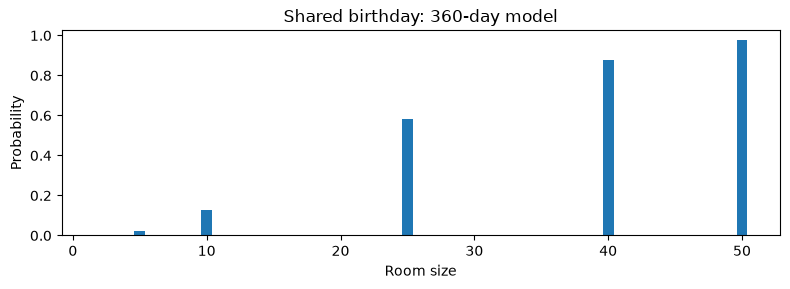

In [24]:
def one_birthday_trial(room_size):
    room = []
    for k in range(room_size):
        room.append([random.choice(months), random.randint(1, 30)])
    for i in range(room_size):
        for j in range(i + 1, room_size):
            if room[i][0] == room[j][0] and room[i][1] == room[j][1]:
                return True
    return False

def estimate_probability(room_size, num_trials):
    assert type(room_size) == int and room_size >= 1, "Room size must be a positive integer"
    assert type(num_trials) == int and num_trials >= 1, "Trials must be a positive integer"
    num_matches = 0
    for trial in range(num_trials):
        if one_birthday_trial(room_size):
            num_matches += 1
    p = num_matches / num_trials
    assert 0 <= p <= 1, "A probability must be between 0 and 1"
    return p

assert one_birthday_trial(1) == False
assert one_birthday_trial(361) == True
print("Known-answer tests passed")
room_sizes = [2, 5, 10, 25, 40, 50]
estimates = []
for size in room_sizes:
    estimates.append(estimate_probability(size, 300))
labeled_bar_plot(room_sizes, estimates, "Room size", "Probability", "Shared birthday: 360-day model")

**解释 / Why it works**

函数内部的生成、两人比较负责一次实验；外面重复调用计算比例。return True 提前结束一次实验；return False 必须在比较循环外。361 人必然重复，不受随机性影响。25 人概率约 0.574；少量模拟会波动，相邻柱偶尔不单调也不一定是 bug。

### 题 23｜Bug hunt：重置、分母、分支（L12/13）

**题目 / Try first**

正确统计月份人数、高分比例和出生季节；解释常见 silent errors。

先自己尝试，再查看下面的参考代码。

In [25]:
month_counts = []
for month in months:
    count = 0
    for name in lab_partners:
        if lab_partners[name]["month"] == month:
            count += 1
    month_counts.append(count)
assert sum(month_counts) == len(lab_partners)
print("Month counts:", month_counts)

num_strong = 0
num_checked = 0
for name in lab_partners:
    num_checked += 1
    if lab_partners[name]["lab_skills"] > 8:
        num_strong += 1
print("Strong fraction:", num_strong / num_checked)

def season_of_month(month):
    if month in ["December", "January", "February"]:
        return "Winter"
    elif month in ["March", "April", "May"]:
        return "Spring"
    elif month in ["June", "July", "August"]:
        return "Summer"
    return "Fall"
assert season_of_month("March") == "Spring"

Month counts: [4, 4, 5, 4, 4, 4, 5, 4, 4, 4, 3, 5]
Strong fraction: 0.14


**解释 / Why it works**

每个月的 count 在外层循环内部重置。总人数每轮累加，成功人数只在条件成立时累加；实验总次数不能随成功次数增加。March 不要同时放入 Winter，否则第一个 if 已成立，后面的 elif 没机会。

### 题 24｜Lab partner 策略、break 和可测试性（L12 Ex8/L13）

**题目 / Try first**

给定 N 和平面分数字典，返回选中者名字、分数、位置。

先自己尝试，再查看下面的参考代码。

In [26]:
def run_one_trial(N, skills_dictionary):
    assert type(N) == int and 0 <= N < len(skills_dictionary), "N is out of range"
    interview_order = list(skills_dictionary.keys())
    random.shuffle(interview_order)
    benchmark = 0
    for position in range(N):
        score = skills_dictionary[interview_order[position]]
        if score > benchmark:
            benchmark = score
    chosen_position = len(interview_order) - 1
    for position in range(N, len(interview_order)):
        name = interview_order[position]
        if skills_dictionary[name] > benchmark:
            chosen_position = position
            break
    chosen_name = interview_order[chosen_position]
    chosen_skill = skills_dictionary[chosen_name]
    assert chosen_skill in list(skills_dictionary.values())
    return chosen_name, chosen_skill, chosen_position

skills_dictionary = {}
for name in lab_partners:
    skills_dictionary[name] = lab_partners[name]["lab_skills"]
print(run_one_trial(10, skills_dictionary))
for trial in range(20):
    name, skill, position = run_one_trial(0, skills_dictionary)
    assert position == 0, "N=0 must choose the first candidate when every score is positive"
print("Position tests passed")

('Duncan', 9.76, 15)
Position tests passed


**解释 / Why it works**

前 N 人只设标准，不选择；剩余人第一个严格超过标准就选并 break，无人超过则选最后一个。缺 break 会变成最后一个合格者。此复习版显式传入字典并返回位置，便于换数据与测试，较原版多一个返回值。benchmark=0 沿用课堂非负分数假设。N=0 与所有分数>0 时必选位置0。

### 题 25｜验证、清洗 -999、人数参数（L13 Ex7/13/16）

**题目 / Try first**

从原始分数建立缺失编码数据，先诊断，再清洗；错误消息应点名具体候选人。

先自己尝试，再查看下面的参考代码。

In [27]:
def check_roster(skills_dictionary, expected_number):
    assert len(skills_dictionary) == expected_number, "The roster is not the expected size"
    for name in skills_dictionary:
        score = skills_dictionary[name]
        assert type(score) == int or type(score) == float, f"{name} has a non-numeric score: {score}"
        assert 0 <= score <= 10, f"{name} has an invalid score: {score}"

updated_skills = skills_dictionary.copy()
for name in ["Craig", "Frankie", "Wendy"]:
    updated_skills[name] = -999

# 仅为演示捕获预期失败；实际数据入口应让检查停止，修复后再继续。
try:
    check_roster(updated_skills, 50)
except AssertionError as error:
    print("Expected diagnostic:", error)

clean_skills = {}
num_dropped = 0
for name in updated_skills:
    score = updated_skills[name]
    if score >= 0:
        clean_skills[name] = score
    else:
        num_dropped += 1
        print("Dropping", name, "- no score on file")
print("Kept", len(clean_skills), "and dropped", num_dropped)
check_roster(clean_skills, 47)
assert updated_skills["Craig"] == -999
assert "Craig" not in clean_skills

Expected diagnostic: Craig has an invalid score: -999
Dropping Craig - no score on file
Dropping Frankie - no score on file
Dropping Wendy - no score on file
Kept 47 and dropped 3


**解释 / Why it works**

-999 是数据约定的缺失编码，Python 会当普通数值处理。dropped 指不复制到新字典，原字典没有删除。print 只提示，不负责删除。len 检查人数：清洗后47不能再要求50。这里确认编码为 -999 后按题意保留非负值；其他数据必须先查说明，不能随意把负数都当缺失。

### 题 26｜异常值如何影响模拟：诊断、画图、重跑（L13 Ex8–14）

**题目 / Try first**

比较含 -999 与清洗后的平均选中分数，并对 N=18 的结果画 histogram。

先自己尝试，再查看下面的参考代码。

Raw min/max: -80.93715 4.436649999999999


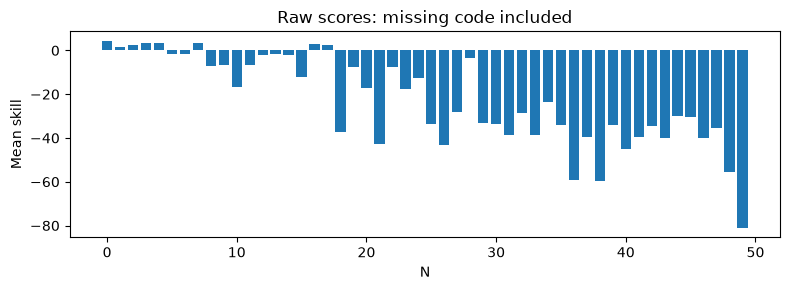

Chosen min/max: -999.0 9.99
Returned -999: 10


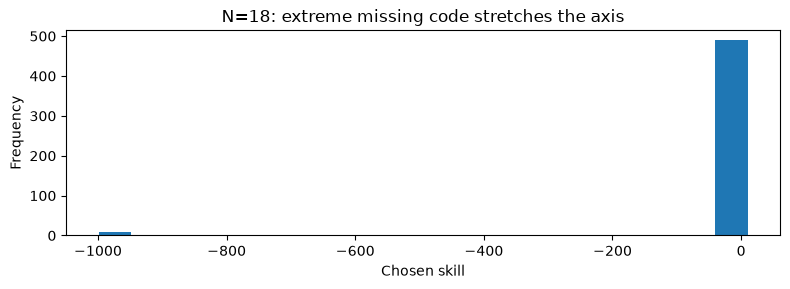

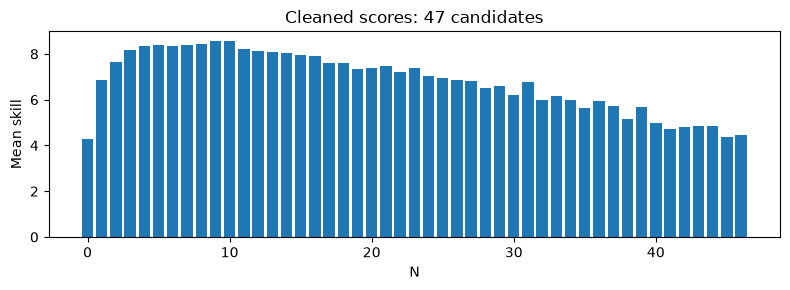

Best N in this run: 9
Mean at this N: 8.559099999999999


In [28]:
def analyze_strategies(scores, num_trials):
    mean_skills = []
    for N in range(len(scores)):
        chosen_skills = []
        for trial in range(num_trials):
            name, skill, position = run_one_trial(N, scores)
            chosen_skills.append(skill)
        mean_skills.append(np.mean(chosen_skills))
    return mean_skills

mean_skills_raw = analyze_strategies(updated_skills, 200)
print("Raw min/max:", np.min(mean_skills_raw), np.max(mean_skills_raw))
labeled_bar_plot(np.arange(50), mean_skills_raw, "N", "Mean skill", "Raw scores: missing code included")
chosen_skills = []
for trial in range(500):
    name, skill, position = run_one_trial(18, updated_skills)
    chosen_skills.append(skill)
print("Chosen min/max:", np.min(chosen_skills), np.max(chosen_skills))
print("Returned -999:", chosen_skills.count(-999))
plt.figure(figsize=(8, 3))
plt.hist(chosen_skills, bins=20)
plt.xlabel("Chosen skill")
plt.ylabel("Frequency")
plt.title("N=18: extreme missing code stretches the axis")
plt.tight_layout()
plt.show()

mean_skills_clean = analyze_strategies(clean_skills, 200)
assert 0 <= np.min(mean_skills_clean) and np.max(mean_skills_clean) <= 10
labeled_bar_plot(np.arange(47), mean_skills_clean, "N", "Mean skill", "Cleaned scores: 47 candidates")
best_N = int(np.argmax(mean_skills_clean))
print("Best N in this run:", best_N)
print("Mean at this N:", mean_skills_clean[best_N])

**解释 / Why it works**

-999 不能超过从0开始的标准，但可能因“没人合格就选最后一个”进入结果。N 较大通常更容易触发默认选择。极端值拉长 histogram 横轴，正常0–10分挤到一起。清洗后N只允许0–46。200次模拟有噪声，argmax 是本次样本最大值，不是已证明的精确最优参数。

### 题 27｜概念题：范围检查与删除数据的局限

**题目**：500 次模拟出现 640 次成功、平均技能11.4、50人中N=63、360天模型下400人重复概率0.98，分别有什么问题？若缺失编码改为999或0会怎样？

**答案**：成功次数不能超过500；平均值不能超过实际最大分（本名单9.99）；N应为0–49；400人必有重复，概率1。

999 会被当成高分选中，或进入前N人把标准变成999，导致无人严格超过而默认选最后一人；通常明显超出0–10。0仍在合法范围内，可能作为最后一人被选中并拉低平均值，范围检查无法识别这个缺失编码。

删除缺失观测会改变候选人构成，并非中性操作。被删者偏弱会令保留样本整体更强；若删掉Todd，最优N变化不能只靠口头推断，需重新比较策略。老师 solutions 对方向给出直观讨论，但不是对一般情形的证明。应根据缺失机制与具体模拟结果解释。

### 题 28｜读代码：为什么结果不对？

| 错误写法 | 修正或解释 |
|---|---|
| 在外层循环前设置 count=0 | 每组开始重新设置，避免跨组累积 |
| `num_trials += 1` 放在成功分支 | 总次数固定；只更新 num_matches |
| 最低分初始化为0，所有分数为正 | 从首个实际分数或正无穷开始 |
| 设标准后仍循环 `range(10)` | 应检查 `range(10, len(order))` |
| `season_counts[pos] = 1` | 使用 `+= 1` |
| 两人比较 j 从 i 开始 | 使用 i+1，避免自己与自己比较 |
| 选择后缺少 break | 会继续选择后面的合格者 |
| 原始数字保存为字符串 | 数值运算前 int/float 转换 |
| 只检查平均值在0–10 | 不足以发现规则或缺失编码错误 |

## 6. Practice quiz A–F 对照与补充

| Quiz | 关键方法 | 本 notebook |
|---|---|---|
| A | 嵌套字典 + running minimum | 题3 |
| B | 两层循环 + 动态分母 + 每日归零 | 题4 |
| C | def + while + return | 题7 |
| D | if/else + Series.apply | 题12 |
| E | KeyError / ValueError + continue | 题18 |
| F | tuple + keyword-only + 极坐标转换 | 题29 |

### Keyword-only 与 default 的区别

`polar=False` 给默认值：不提供时使用False；单独的 `*` 规定后面的参数只能写名字传入。

```python
def cord_dist(point1, point2, *, polar=False):
    ...
```

- `cord_dist((0,0), (3,4))`：使用默认False。
- `cord_dist((1,0), (1,np.pi/2), polar=True)`：正确。
- `cord_dist((1,0), (1,np.pi/2), True)`：TypeError。

polar 是自选参数名，意思是极坐标；不是 Python 特殊关键词。直角坐标是(x,y)，极坐标是(r,theta)。NumPy 三角函数使用弧度：90°=np.pi/2。

### 题 29｜两种坐标下的距离（Quiz F）

**题目 / Try first**

默认按直角坐标计算；polar=True 时先转换再计算距离，只限制 polar 为 keyword-only。

先自己尝试，再查看下面的参考代码。

In [29]:
def euclidean_dist(point1, point2):
    x1, y1 = point1
    x2, y2 = point2
    return np.sqrt((x1-x2)**2 + (y1-y2)**2)

def cord_dist(point1, point2, *, polar=False):
    if polar:
        r1, theta1 = point1
        r2, theta2 = point2
        point1 = (r1*np.cos(theta1), r1*np.sin(theta1))
        point2 = (r2*np.cos(theta2), r2*np.sin(theta2))
    return euclidean_dist(point1, point2)

print("Cartesian:", cord_dist((0,0), (3,4)))
print("Polar:", cord_dist((1,0), (1,np.pi/2), polar=True))
assert np.isclose(cord_dist((0,0), (3,4)), 5)
assert np.isclose(cord_dist((1,0), (1,np.pi/2), polar=True), np.sqrt(2))

Cartesian: 5.0
Polar: 1.414213562373095


**解释 / Why it works**

极坐标按 x=r*cos(theta)、y=r*sin(theta) 转换。return 放在 if 外，让默认False时也能返回距离。两个点可按位置传入，polar 必须写名字。

## 7. 可选交互练习

默认开关 False，Run All 会跳过等待输入。想练习时改为 True，单独运行相应 cell。函数必须先定义，再调用。

**skill函数**：执行 `skill = ask_for_skill()`，在出现的输入框输入6.72；不要调用 ask_for_skill(6.72)。

**参数辨析**：`ask_for_N(50)` 的50表示候选人总数；程序会另外询问N。`run_one_trial(20, scores)` 的20才是设标准时先观察的人数。

In [30]:
RUN_SKILL_INPUT = False
if RUN_SKILL_INPUT:
    skill = ask_for_skill()
    print("Your score:", skill)
    print("Candidates who beat it:", count_better(skill))

### 题 30｜验证整数输入 + 综合模拟（L12 Ex8/L13 Ex6）

**题目 / Try first**

编写通用整数询问函数；用于N、模拟次数和生日人数。默认不启动交互。

先自己尝试，再查看下面的参考代码。

In [31]:
def ask_for_whole_number(question, smallest, largest):
    while True:
        typed = input(question)
        try:
            value = int(typed)
        except ValueError:
            print("Please enter a whole number.")
            continue
        if value < smallest or value > largest:
            print(f"Enter a value from {smallest} to {largest}.")
            continue
        return value

def ask_for_N(num_candidates):
    return ask_for_whole_number("Choose N: ", 0, num_candidates - 1)

RUN_PARTNER_INPUT = False
if RUN_PARTNER_INPUT:
    N = ask_for_N(len(clean_skills))
    num_trials = ask_for_whole_number("Number of trials (1–10000): ", 1, 10000)
    results = []
    for trial in range(num_trials):
        name, score, position = run_one_trial(N, clean_skills)
        results.append(score)
    print("N:", N, "Trials:", num_trials, "Mean skill:", np.mean(results))

RUN_BIRTHDAY_INPUT = False
if RUN_BIRTHDAY_INPUT:
    room_size = ask_for_whole_number("Room size (1–400): ", 1, 400)
    num_trials = ask_for_whole_number("Trials (1–10000): ", 1, 10000)
    p = estimate_probability(room_size, num_trials)
    print("Estimated probability:", p)
    assert 0 <= p <= 1

**解释 / Why it works**

typed始终是字符串；try检查能否转整数；if检查范围；continue重新询问；return结束整个函数，不需要break。模拟次数上限10000沿用老师solutions的交互示例，避免不小心输入极大次数。

## 考前最后一页：必记模板

| 想做什么 | 代码模式 |
|---|---|
| 查字典 | `d[key]` / `d[name][field]` |
| 遍历取值 | `for key in d:` 然后 `value = d[key]` |
| 复制有效数据 | `clean = {}` 然后条件成立时 `clean[name] = score` |
| 更新最值 | 比较后同时更新 name 和 value |
| 按组求平均 | 每组重置 total；除以实际组人数 |
| 定义函数 | `def f(...): ... return value` |
| 接收两对象 | `a, b = f(...)` |
| 一行函数 | `fn = lambda x: expression` |
| 整列处理 | `df["col"].apply(fn)` |
| 预期异常 | `try: ... except SpecificError: ...` |
| 反复询问 | `while True` + input + 转换 + 范围检查 + return |
| 检查假设 | `assert condition, "message"` |
| 不同两人配对 | `j in range(i+1, n)` |
| 找最大值位置 | `np.argmax(values)`，不等于最大值本身 |
| 原地修改 | append、下标赋值；不要求 return |
| 新对象 | `lst + [...]` 后需 return 并接收 |

**容易混淆**：`=` 是赋值，`==` 是比较；`>` 不包含相等；print 不会把结果返回给调用者；return会结束函数；break只结束当前循环；continue进入下一轮。字典中有订单商品不等于价格表中有卖。范围合法不等于缺失编码已处理。

### 复习来源
- Lecture9 copy(1).ipynb：字典与 DataFrame。
- Lecture10 copy.ipynb、Lecture10-exercises(1).ipynb：函数与扩展练习。
- Lecture11.ipynb：lambda、apply、绘图和 mutation。
- Lecture12 copy(1).ipynb：异常与交互输入。
- Lecture13 copy(1).ipynb、Lecture13-solutions.ipynb：assert、debugging、缺失分数案例。
- practice_quiz_3.ipynb：A–F综合题。

本文件是整理与适度改编的复习版，使用唯一函数名或显式数据参数减少互相覆盖；不是把原notebook机械合并。所有示例答案都放在题目之后，可逐题修改练习。

## 8. Lab 5 — `*`、`*args`、`**kwargs`

Lab 5 的重点是 **调用函数时，输入如何与参数对应**。Quiz F 的 polar 是这一节 keyword-only 的直接应用。

| 位置与写法 | 作用 | 得到的对象 |
|---|---|---|
| 定义中单独 `*` | 后面的参数必须用名字传入 | 不收集数据 |
| 定义中 `*args` | 收集额外位置参数 | tuple |
| 定义中 `**kwargs` | 收集额外关键词参数 | dictionary |
| 调用中 `*sequence` | 将序列展开为位置实参 | 如 f(*[2,3]) 等于 f(2,3) |
| 调用中 `**mapping` | 将字典展开为关键词实参 | 如 f(**{"x":2,"y":3}) |

`args`、`kwargs` 是惯例名字，真正起作用的是星号。不能因为函数里写了 kwargs 就认为任意库函数都接受任意关键词。

**默认值与 keyword-only 不是一回事**：`name=None` 表示可省略；`*, name=None` 除了可省略，还要求传入时写 name=。`*` 不会检查 name 的值是否真的是人名，例如 name=1989 仍可以传入。

普通显式调用中，位置参数放在关键词参数之前；关键词之间顺序可调整。`birthday(month="June", 20)` 是 SyntaxError，而少写必需参数或给 keyword-only 传位置值通常是 TypeError。

注意 lab 开头对 plt.plot 的说明容易误读：scalex、scaley、data 有默认值，不是每次必须提供的三个输入；help 中带默认值通常表示可省略。

### 题 31｜Keyword-only 与调用顺序（Lab Ex1–2）

**题目 / Try first**

定义生日函数，只有 name 必须写名字；再定义全部参数必须写名字的版本。判断哪些调用合法。

先自己尝试，再查看下面的参考代码。

In [32]:
def birthday(month, day, *, name=None):
    if name is None:
        print(f"Your birthday is {month} {day}.")
    else:
        print(f"{name}, your birthday is {month} {day}.")

birthday("June", 20)
birthday("June", day=20, name="Peter")
birthday(day=20, name="Peter", month="June")

def birthday_all_named(*, month, day, name=None):
    birthday(month, day, name=name)

birthday_all_named(month="June", day=20, name="Peter")
# 错误示例保留为注释，避免 Run All 中断：
# birthday("June", 20, "Peter")                 # TypeError
# birthday(month="June", 20, name="Peter")      # SyntaxError
# birthday_all_named("June", 20)               # TypeError

Your birthday is June 20.
Peter, your birthday is June 20.
Peter, your birthday is June 20.
Peter, your birthday is June 20.


**解释 / Why it works**

单独 * 后面的 name 必须用 name= 传入，但 month、day 仍可按位置或名字传入。把 * 放到第一个参数前，所有参数都是 keyword-only。使用 name is None 判断未提供名称；None 不等于字符串 "None"。

### 题 32｜*args 与安全的第四个参数（Lab Ex4–5）

**题目 / Try first**

观察 args 类型；至少四个参数时打印第四个，否则提示不足。

先自己尝试，再查看下面的参考代码。

In [33]:
def show_args(*args):
    print("args:", args, "type:", type(args), "length:", len(args))

def show_fourth(*args):
    if len(args) >= 4:
        print(args[3])
    else:
        print("Not enough arguments")

show_args("hello", [1, 2, 3], 6)
show_args()
show_fourth(5, 19, "Emory", -1)
show_fourth(12, 19, 0, 2, 55)
show_fourth(99, 12, "bird")
show_fourth()

args: ('hello', [1, 2, 3], 6) type: <class 'tuple'> length: 3
args: () type: <class 'tuple'> length: 0
-1
2
Not enough arguments
Not enough arguments


**解释 / Why it works**

args 为 tuple，长度由实际传入的位置参数个数决定；类型可混合。没有参数时是空 tuple ()。第四个元素索引是3；不做长度检查时，少于4个会 IndexError。show_args([1,2,3]) 是一个list实参，show_args(1,2,3) 是三个实参。

### 题 33｜按位置实参数量选择图（Lab Application）

**题目 / Try first**

一个输入画 histogram，两个输入画 bar，其余数量打印提示。

先自己尝试，再查看下面的参考代码。

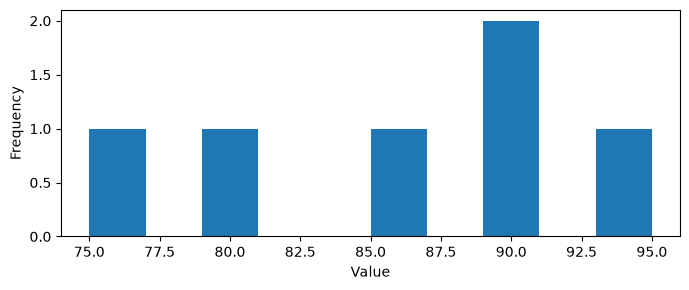

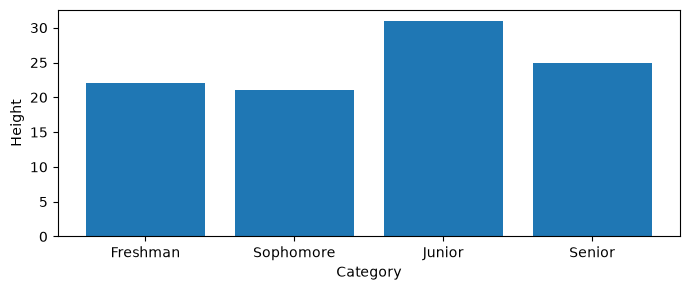

Provide one or two arguments.


In [34]:
def make_plot(*args):
    if len(args) not in [1, 2]:
        print("Provide one or two arguments.")
        return
    plt.figure(figsize=(7, 3))
    if len(args) == 1:
        plt.hist(args[0])
        plt.xlabel("Value")
        plt.ylabel("Frequency")
    else:
        plt.bar(args[0], args[1])
        plt.xlabel("Category")
        plt.ylabel("Height")
    plt.tight_layout()
    plt.show()

make_plot([75, 80, 85, 90, 90, 95])
make_plot(["Freshman", "Sophomore", "Junior", "Senior"], [22, 21, 31, 25])
make_plot()

**解释 / Why it works**

一个list输入代表分布数据，hist自动统计各区间频数；两个输入分别给类别与柱高。选择图的规则来自这个自定义函数的 if，不是 *args 自己决定。参数个数无效时 return 提前结束。

### 题 34｜print 的 sep（Lab Ex6）

**题目 / Try first**

只在代码里显式输入一次连字符，打印 Port-au-Prince, Haiti。

先自己尝试，再查看下面的参考代码。

In [35]:
print("Port", "au", "Prince, Haiti", sep="-")
print("score:", 95, "passed:", True, sep="*")
print("score:", 95, "passed:", True, "*")

Port-au-Prince, Haiti
score:*95*passed:*True
score: 95 passed: True *


**解释 / Why it works**

sep="-" 不是打印项，而是设置各打印项之间的分隔符，重复用于两个间隔。把 "*" 作为最后一个位置实参，则只是增加一个待打印项，其他项仍使用默认空格分隔。

### 题 35｜**kwargs：字典与不同分支（Lab Ex7 + student_info）

**题目 / Try first**

根据是否有 name 与 major 打印三种介绍。

先自己尝试，再查看下面的参考代码。

In [36]:
def show_kwargs(**kwargs):
    print("kwargs:", kwargs, "type:", type(kwargs))
    print("keys:", list(kwargs.keys()))
    print("values:", list(kwargs.values()))

def student_info(**kwargs):
    if "name" in kwargs:
        if "major" in kwargs:
            print(f"Hi, I'm {kwargs['name']} and I'm majoring in {kwargs['major']}!")
        else:
            print(f"Hi, I'm {kwargs['name']}!")
    else:
        print("Hi!")

show_kwargs(name="Annie", major="Data Science")
show_kwargs()
student_info(name="Annie", major="Data Science")
student_info(name="Annie", age=22)
student_info(major="Data Science")

kwargs: {'name': 'Annie', 'major': 'Data Science'} type: <class 'dict'>
keys: ['name', 'major']
values: ['Annie', 'Data Science']
kwargs: {} type: <class 'dict'>
keys: []
values: []
Hi, I'm Annie and I'm majoring in Data Science!
Hi, I'm Annie!
Hi!


**解释 / Why it works**

kwargs 是字典，关键词名成为字符串 key，关键词的值成为 value；无关键词时是 {}。先用 in 检查 key 再访问，避免 KeyError。函数接收 age 但没有使用它，所以不会打印。只有 major 没有 name 时按题意输出 Hi!。

### 题 36｜可选图形设置（Lab Ex8）

**题目 / Try first**

固定两个数据输入，通过 kwargs 可选设置 color 和 grid。

先自己尝试，再查看下面的参考代码。

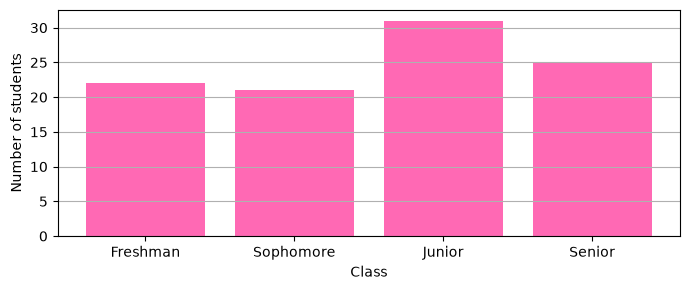

In [37]:
def make_bar_plot(categories, height, **kwargs):
    plt.figure(figsize=(7, 3))
    if "color" in kwargs:
        plt.bar(categories, height, color=kwargs["color"])
    else:
        plt.bar(categories, height)
    if "grid" in kwargs and kwargs["grid"]:
        plt.grid(axis="y")
    plt.xlabel("Class")
    plt.ylabel("Number of students")
    plt.tight_layout()
    plt.show()

make_bar_plot(["Freshman", "Sophomore", "Junior", "Senior"],
              [22, 21, 31, 25], color="hotpink", grid=True)

**解释 / Why it works**

categories、height 对应明确参数；额外的 color、grid 收集到 kwargs。先检查是否存在，再用值；grid=False 不显示网格。这里仅使用自定义函数明确处理的设置，没有盲目把所有 kwargs 交给 plt.bar。

### 题 37｜收集与展开的区别（Lab 延伸对照）

**题目 / Try first**

比较 f(list)、f(*list)，以及 keywords 与 **dictionary。

先自己尝试，再查看下面的参考代码。

In [38]:
def collect(*values):
    return values
print("One list argument:", collect([2, 4]))
print("Two positional arguments:", collect(*[2, 4]))

options = {"month": "June", "day": 20, "name": "Peter"}
birthday(**options)

# 定义时收集，调用时展开；显式参数仍然先匹配到自己的名字。
def describe(first, *args, label="Example", **kwargs):
    return first, args, label, kwargs
print(describe(1, 2, 3, label="Demo", color="blue"))

One list argument: ([2, 4],)
Two positional arguments: (2, 4)
Peter, your birthday is June 20.
(1, (2, 3), 'Demo', {'color': 'blue'})


**解释 / Why it works**

定义中的 *values 收集为tuple，调用中的 *[2,4] 展开成2和4。调用 **options 展开成 month=...、day=...、name=...。describe 中 first接收1，args接收(2,3)，label接收Demo，kwargs只有color；*args后面的label也是keyword-only。

### Lab 5 考前自测

1. `def f(*, x, y)`：两个必需的 keyword-only 参数。
2. `def f(*values)`：收集位置实参到 tuple，名字不必叫 args。
3. `def f(**options)`：收集关键词实参到字典，名字不必叫 kwargs。
4. `def f(x=1)`：有默认值，但仍允许按位置传入。
5. `def f(*, x=1)`：既有默认值，又只能按名字传入。
6. `f()` 是否合法由定义决定；*args、**kwargs 可以分别收集空tuple和空字典，普通必需参数不能缺。
7. 同一参数不能既按位置又按名字重复传入，例如 `f(2,x=3)`（若第一个参数名为x）会TypeError。

**新增来源**：Lab_05-with-solutions.ipynb。实验题号按原lab标注；该文件从参数演示直接跳到Exercise 4，没有单独命名的Exercise 3。